# Hàm kích hoạt

*Bài 9, mục 9.1.2.* Mỗi nơ-ron tính $z = \mathbf{w}^T\mathbf{x} + b$ rồi đưa qua hàm kích hoạt $a = f(z)$. Hàm kích hoạt phi tuyến giúp mạng biểu diễn được quan hệ phi tuyến.

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def step(z):
    return (z >= 0).astype(float)


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def tanh(z):
    return np.tanh(z)


def relu(z):
    return np.maximum(0, z)


def leaky_relu(z, alpha=0.01):
    return np.where(z >= 0, z, alpha * z)


# Đạo hàm, dùng trong lan truyền ngược (mục 9.1.3)
def sigmoid_derivative(z):
    s = sigmoid(z)
    return s * (1 - s)                       # sigma'(z) = sigma(z)(1 - sigma(z))


def tanh_derivative(z):
    return 1 - np.tanh(z)**2


def relu_derivative(z):
    return (z > 0).astype(float)

## 1. Giá trị tại một số điểm

In [2]:
z = np.array([-3.0, -1.0, 0.0, 1.0, 3.0])
print('z           :', z)
print('step        :', step(z))
print('sigmoid     :', sigmoid(z).round(4))
print('tanh        :', tanh(z).round(4))
print('ReLU        :', relu(z))
print('Leaky ReLU  :', leaky_relu(z))

z           : [-3. -1.  0.  1.  3.]
step        : [0. 0. 1. 1. 1.]
sigmoid     : [0.0474 0.2689 0.5    0.7311 0.9526]
tanh        : [-0.9951 -0.7616  0.      0.7616  0.9951]
ReLU        : [0. 0. 0. 1. 3.]
Leaky ReLU  : [-0.03 -0.01  0.    1.    3.  ]


## 2. Đồ thị hàm và đạo hàm

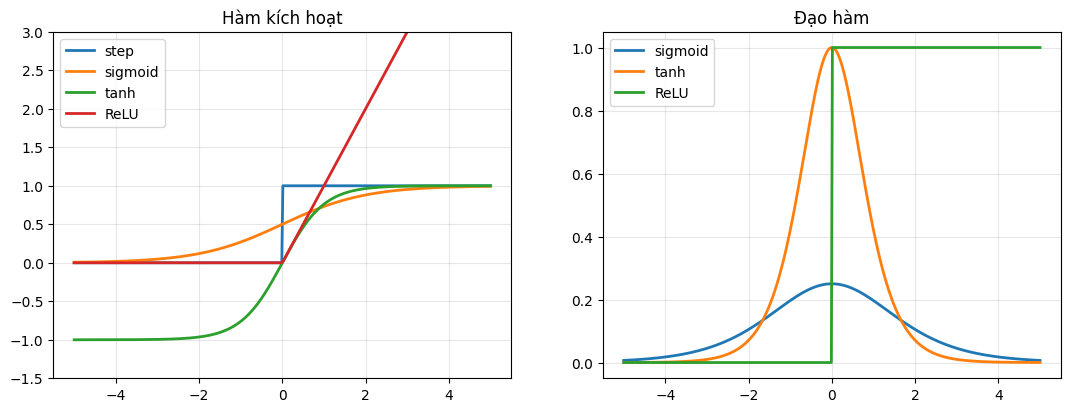

Đạo hàm lớn nhất của sigmoid: 0.25 (tại z = 0)


In [3]:
z = np.linspace(-5, 5, 400)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, f in [('step', step), ('sigmoid', sigmoid), ('tanh', tanh), ('ReLU', relu)]:
    axes[0].plot(z, f(z), lw=2, label=name)
axes[0].set_title('Hàm kích hoạt'); axes[0].legend(); axes[0].grid(alpha=0.3); axes[0].set_ylim(-1.5, 3)
for name, df in [('sigmoid', sigmoid_derivative), ('tanh', tanh_derivative), ('ReLU', relu_derivative)]:
    axes[1].plot(z, df(z), lw=2, label=name)
axes[1].set_title('Đạo hàm'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.show()
print('Đạo hàm lớn nhất của sigmoid: %.2f (tại z = 0)' % sigmoid_derivative(0.0))

Đạo hàm sigmoid không vượt quá 0.25 và gần 0 khi $|z|$ lớn (bão hòa). Riêng tích đạo hàm kích hoạt qua $L$ lớp không vượt quá $0.25^L$. **Gradient đầy đủ còn phụ thuộc các ma trận trọng số**, nên đây không phải cận trên của toàn bộ gradient; tích các Jacobian có thể làm gradient tiêu biến hoặc bùng nổ.

In [4]:
for n_layers in [1, 5, 10, 20]:
    print('%2d lớp sigmoid: tích đạo hàm kích hoạt tối đa 0.25^%d = %.2e' % (n_layers, n_layers, 0.25**n_layers))

 1 lớp sigmoid: tích đạo hàm kích hoạt tối đa 0.25^1 = 2.50e-01
 5 lớp sigmoid: tích đạo hàm kích hoạt tối đa 0.25^5 = 9.77e-04
10 lớp sigmoid: tích đạo hàm kích hoạt tối đa 0.25^10 = 9.54e-07
20 lớp sigmoid: tích đạo hàm kích hoạt tối đa 0.25^20 = 9.09e-13


## 3. Softmax cho phân loại nhiều lớp

$\text{softmax}(\mathbf{z})_k = \dfrac{e^{z_k}}{\sum_j e^{z_j}}$ biến vector điểm số thành phân phối xác suất (các phần tử dương, tổng bằng 1). Trừ đi $\max_j z_j$ trước khi lấy mũ để tránh tràn số; kết quả không đổi.

In [5]:
def softmax(z):
    e = np.exp(z - np.max(z))
    return e / e.sum()


scores = np.array([2.0, 1.0, 0.1])
p = softmax(scores)
print('Điểm số :', scores)
print('Xác suất:', p.round(4), ' tổng =', p.sum())
print('softmax([1000, 999, 998.1]) =', softmax(np.array([1000, 999, 998.1])).round(4))

Điểm số : [2.  1.  0.1]
Xác suất: [0.659  0.2424 0.0986]  tổng = 1.0
softmax([1000, 999, 998.1]) = [0.659  0.2424 0.0986]


## 4. Vì sao cần hàm kích hoạt phi tuyến?

Hai lớp tuyến tính liên tiếp $\mathbf{W}_2(\mathbf{W}_1\mathbf{x} + \mathbf{b}_1) + \mathbf{b}_2 = (\mathbf{W}_2\mathbf{W}_1)\mathbf{x} + (\mathbf{W}_2\mathbf{b}_1 + \mathbf{b}_2)$ chỉ tương đương **một** lớp tuyến tính.

In [6]:
rng = np.random.default_rng(0)
W1, b1 = rng.normal(size=(4, 3)), rng.normal(size=4)
W2, b2 = rng.normal(size=(2, 4)), rng.normal(size=2)
x = rng.normal(size=3)
two_layers = W2 @ (W1 @ x + b1) + b2
one_layer = (W2 @ W1) @ x + (W2 @ b1 + b2)
print('Hai lớp tuyến tính:', two_layers.round(4))
print('Một lớp tương đương:', one_layer.round(4))
print('Có ReLU ở giữa     :', (W2 @ relu(W1 @ x + b1) + b2).round(4))

Hai lớp tuyến tính: [1.961  2.5786]
Một lớp tương đương: [1.961  2.5786]
Có ReLU ở giữa     : [1.6902 0.4056]
